# Are SHAP Feature Rankings Robust to Train–Test Split Ratios? A Repeated-Split Study Using Random Forest on Two Clinical Datasets
### Experiment 2 — UCI Combined Heart Disease Dataset (Random Forest)
### (Heart Disease Data of Cleveland, Hungary, Switzerland, and the VA Long Beach, deduplicated)

**Purpose.** This is **Experiment 2** in a two-dataset comparative study, alongside
Experiment 1 (Random Forest / Pima Indians Diabetes Dataset). It re-runs the same
experimental protocol — five split ratios, 20 matched repeated runs, leakage-safe
pipeline, PR-AUC-tuned Random Forest, SHAP stability battery, Friedman + Nemenyi — on
a second clinical prediction dataset that differs from Pima on several axes: combined
multi-site data (Cleveland, Hungary, Switzerland, and the VA Long Beach) rather than a single
site, ~3x the observations, and a materially different mix of numeric vs.
nominal-categorical predictors.

**No SMOTE; class weighting instead.** Neither experiment uses SMOTE. Class balance is
handled with `RandomForestClassifier(class_weight="balanced")` in both. The Heart classes
are close to balanced after deduplication (43.6% / 56.4%), so the weights are close to
neutral here, but using the same mechanism keeps the protocol identical to Experiment 1.
The one deliberate preprocessing difference is imputation: Experiment 1 (Pima) uses
MICE because of its heavy missingness, whereas this dataset has far less missingness
and keeps median imputation.

**Random Forest is the sole algorithm in both experiments.** Holding the algorithm
fixed means any differences observed between Experiment 1 and Experiment 2 can be
attributed to the dataset, not to a simultaneous change of algorithm *and* dataset.

**Research questions:** Does the train–test split ratio affect (a) Random Forest
predictive performance and (b) the stability of SHAP-based feature-importance
rankings, in heart disease prediction? Is the best-performing ratio also the one with
the most stable explanations (the "performance–stability gap")? And do the answers
found in Experiment 1 (diabetes) generalize to this second clinical dataset?

## Study design

Identical to Experiment 1 except for the dataset, its dataset-specific preprocessing
decisions (Sections 2–6), and the imputation method (median here, MICE in Experiment 1).

**Five stratified split ratios:** 50:50, 60:40, 70:30, 80:20, 90:10.

**Each ratio is run 20 times** with different (but matched) random seeds — seed
*k* produces the k-th split under every ratio, enabling a **Friedman test** across
ratios with **Nemenyi** post-hoc pairwise comparisons if significant.

**Design choice — retuning per repeat:** `RandomizedSearchCV` is re-run
independently for every (seed, ratio) combination, exactly as in Experiment 1, so
that variability across repeats reflects both sampling variability and search
stochasticity in both experiments equally, keeping the two experiments comparable
on this axis.

**Compute budget:** 5 ratios × 20 repeats × (`RandomizedSearchCV`: `N_ITER` ×
`CV_FOLDS` fits). `N_ITER=25`, `CV_FOLDS=5` are kept identical to Experiment 1 —
this dataset is only ~3x Pima's size, so the same budget is tractable here.

## Dataset-specific decisions made for this experiment (see Sections 2–6 for detail)

1. **Duplicates are dropped** (723 of 2,943 rows, 24.6%) — exact duplicate
   rows are not independent observations, and would let the same record fall in both
   train and test.
2. **Zero-as-missing applies to two columns only** (`Cholesterol`, `RestingBP`),
   far narrower than Experiment 1's five affected columns.
3. **The categorical branch is genuinely exercised this time.** Five features are
   categorical (`Sex`, `ChestPainType`, `FastingBS`, `RestingECG`, `ExerciseAngina`)
   and are one-hot encoded — in Experiment 1, the categorical branch was a structural
   no-op (Pima has no categorical features).
4. **Class weighting, no SMOTE.** Classes are nearly balanced (43.6% / 56.4% after
   cleaning), so `class_weight="balanced"` is close to neutral, and no resampling step
   is used. PR-AUC is still used for tuning and as the primary metric, to keep the
   evaluation protocol identical to Experiment 1.

## Pipeline overview

1. Load & inspect data
2. Clean (biologically-impossible zeros → NaN; drop exact duplicate rows)
3. Outlier detection (IQR report) — outliers are **capped, never dropped**
4. Leakage-safe pipeline: impute (median) → cap outliers (IQR, numeric only) →
   scale / one-hot → Random Forest (`class_weight="balanced"`), all fit on training
   folds/partitions only
5. For every (seed, ratio) pair: tune (`RandomizedSearchCV`, PR-AUC scoring) →
   evaluate on held-out test → compute SHAP (`TreeExplainer`) → store performance +
   feature ranking
6. Aggregate performance across repeats per ratio (mean ± 95% CI); Friedman +
   Nemenyi for formal comparison across ratios
7. Aggregate SHAP rankings across repeats per ratio; pairwise **stability** across all
   10 ratio-pairs using Kendall's τ, Spearman's ρ, Jaccard (Top-3 and Top-5), and
   mean absolute rank difference
8. Performance–stability gap check: does the best-performing ratio also produce the
   most stable explanations?
9. **Cross-experiment comparison** (reported in the manuscript, not in this notebook): how do
   Experiment 1 and Experiment 2's answers to the same two research questions compare?


## 1. Imports

In [1]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kendalltau, spearmanr, friedmanchisquare, loguniform, randint

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
)


import shap

# Post-hoc Nemenyi test (pip install scikit-posthocs if not already installed)
import scikit_posthocs as sp

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_style("whitegrid")


## 2. Load Data

UCI Combined Heart Disease Dataset: 2,943 raw observations merging five source
cohorts (Cleveland, Hungarian, Switzerland, VA Long Beach, Statlog), 10 clinical
predictors, binary outcome. Loaded from a local CSV bundled alongside this notebook.


In [2]:

DATA_PATH = "heart_disease_combined.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()


Shape: (2943, 11)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,HeartDisease
0,40,1,1,140,289,0,0,172,0,0.0,0
1,49,0,2,160,180,0,0,156,0,1.0,1
2,37,1,1,130,283,0,1,98,0,0.0,0
3,48,0,3,138,214,0,0,108,1,1.5,1
4,54,1,2,150,195,0,0,122,0,0.0,0


## 3. Inspection

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2943 entries, 0 to 2942
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             2943 non-null   int64  
 1   Sex             2943 non-null   int64  
 2   ChestPainType   2943 non-null   int64  
 3   RestingBP       2943 non-null   int64  
 4   Cholesterol     2943 non-null   int64  
 5   FastingBS       2943 non-null   int64  
 6   RestingECG      2943 non-null   int64  
 7   MaxHR           2943 non-null   int64  
 8   ExerciseAngina  2943 non-null   int64  
 9   Oldpeak         2943 non-null   float64
 10  HeartDisease    2943 non-null   int64  
dtypes: float64(1), int64(10)
memory usage: 253.0 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2943.0,52.381923,13.037189,20.0,44.0,54.0,61.0,80.0
Sex,2943.0,0.748556,0.433917,0.0,0.0,1.0,1.0,1.0
ChestPainType,2943.0,1.363575,1.142614,0.0,0.0,1.0,2.0,3.0
RestingBP,2943.0,138.698267,24.623198,0.0,120.5,134.0,150.0,200.0
Cholesterol,2943.0,253.515121,112.724716,0.0,204.0,248.0,306.0,603.0
FastingBS,2943.0,0.225280,0.417838,0.0,0.0,0.0,0.0,1.0
RestingECG,2943.0,0.626911,0.713650,0.0,0.0,0.0,1.0,2.0
MaxHR,2943.0,144.040095,28.446327,60.0,124.0,145.0,165.0,202.0
ExerciseAngina,2943.0,0.412504,0.492369,0.0,0.0,0.0,1.0,1.0
Oldpeak,2943.0,1.570031,1.585102,-2.6,0.1,1.2,2.4,6.2


HeartDisease
1    1614
0    1329
Name: count, dtype: int64
HeartDisease
1    0.5484
0    0.4516
Name: proportion, dtype: float64


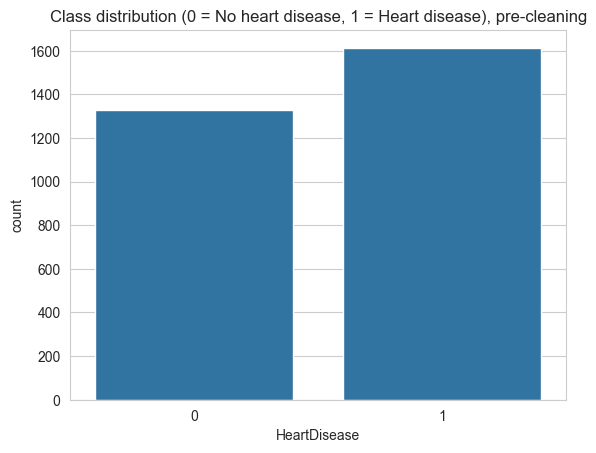

In [5]:

print(df["HeartDisease"].value_counts())
print(df["HeartDisease"].value_counts(normalize=True).round(4))

sns.countplot(x="HeartDisease", data=df)
plt.title("Class distribution (0 = No heart disease, 1 = Heart disease), pre-cleaning")
plt.show()


In [6]:
# Cholesterol and RestingBP of 0 are physiologically implausible and are used in
# this dataset as a missing-data placeholder (a documented quirk of the Statlog/VA
# subset in particular). Unlike Pima, this affects only two columns.
zero_as_missing_cols = ["Cholesterol", "RestingBP"]

zero_counts = (df[zero_as_missing_cols] == 0).sum()
zero_pct = (100 * zero_counts / len(df)).round(1)

print("Zero-value counts / percentage (treated as missing) per column:")
print(pd.DataFrame({"n_zero": zero_counts, "pct_zero": zero_pct}))

# Note, for the record: Oldpeak also contains zeros (~24%) and even negative values,
# but 0 is a genuine, clinically meaningful reading for Oldpeak (no ST-segment
# depression) rather than a missing-data placeholder, so it is NOT touched here.
print("\nOldpeak zeros (genuine, NOT treated as missing):", (df["Oldpeak"] == 0).sum(),
      f"({100*(df['Oldpeak']==0).sum()/len(df):.1f}%)")


Zero-value counts / percentage (treated as missing) per column:
             n_zero  pct_zero
Cholesterol     225       7.6
RestingBP         1       0.0

Oldpeak zeros (genuine, NOT treated as missing): 716 (24.3%)


## 4. Cleaning

Zeros in `Cholesterol` and `RestingBP` are converted to `NaN`. Imputation itself
happens **inside** the modelling pipeline (median, fit on training data only per
repeat) — not here — to avoid leaking test-partition information into training,
exactly as in Experiment 1.

**Duplicates — dropped, with justification specific to this dataset.** This release
merges five originally separate cohorts (Cleveland, Hungarian, Switzerland, VA Long
Beach, Statlog). Exact-duplicate rows at the scale found here are a documented
artifact of that merge process (overlapping records/re-releases across the
constituent source files), not independently-arising identical patients. Retaining
these rows would let the same underlying record appear in both the training and
test partition of a given split by chance, silently inflating held-out performance
— a leakage channel distinct from, but analogous to, the leakage the rest of this
pipeline is designed to prevent.



In [7]:

df_clean = df.copy()
df_clean[zero_as_missing_cols] = df_clean[zero_as_missing_cols].replace(0, np.nan)

n_before = len(df_clean)
n_dupes = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
n_after = len(df_clean)

print(f"Rows before dedup: {n_before}")
print(f"Exact duplicate rows removed: {n_dupes} ({100*n_dupes/n_before:.1f}%)")
print(f"Rows after dedup: {n_after}")

print("\nMissing values after zero->NaN conversion:")
print(df_clean.isna().sum())

print("\nClass balance after cleaning:")
print(df_clean["HeartDisease"].value_counts())
print(df_clean["HeartDisease"].value_counts(normalize=True).round(4))


Rows before dedup: 2943
Exact duplicate rows removed: 723 (24.6%)
Rows after dedup: 2220

Missing values after zero->NaN conversion:
Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       225
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
HeartDisease        0
dtype: int64

Class balance after cleaning:
HeartDisease
1    1252
0     968
Name: count, dtype: int64
HeartDisease
1    0.564
0    0.436
Name: proportion, dtype: float64


In [8]:

FEATURES = [c for c in df_clean.columns if c != "HeartDisease"]
TARGET = "HeartDisease"

# Unlike Pima (no categorical features), the categorical branch is genuinely
# exercised here. These features are nominal / binary-coded, so OneHotEncoder is
# used rather than passing them through as numeric integers.
numeric_features = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
categorical_features = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina"]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Categorical features: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina']


## 5. Outlier Detection

Same policy as Experiment 1: rows are **never dropped** for being outliers — every
row lost is signal that cannot be recovered. Outliers in the five numeric features
are **capped (winsorized)**, fit on training data only inside the pipeline
(Section 6), so every partition retains its full intended sample size. Categorical
features are not subject to IQR-based capping.


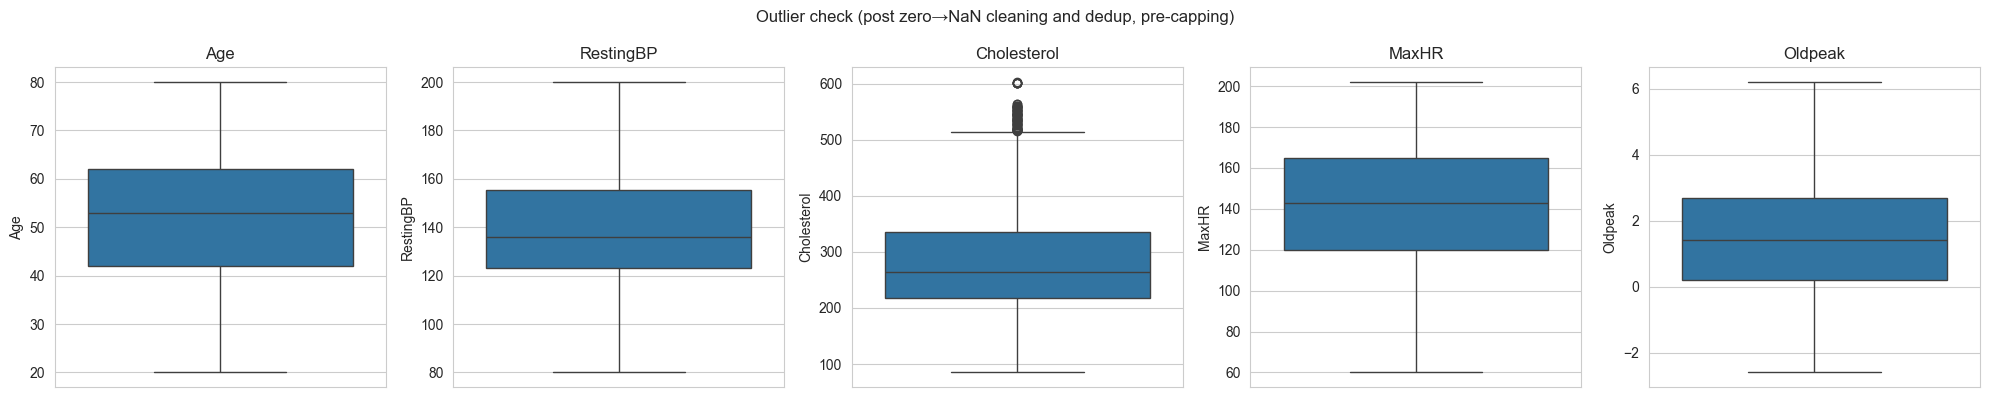

In [9]:

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes.ravel(), numeric_features):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Outlier check (post zero\u2192NaN cleaning and dedup, pre-capping)")
plt.tight_layout()
plt.show()


In [10]:

def iqr_outlier_report(data, cols, k=1.5):
    rows = []
    for col in cols:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - k * iqr, q3 + k * iqr
        n_outliers = ((data[col] < lower) | (data[col] > upper)).sum()
        rows.append({
            "Feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
            "Lower_bound": lower, "Upper_bound": upper,
            "N_outliers": n_outliers,
            "Pct_outliers": round(100 * n_outliers / len(data), 2),
        })
    return pd.DataFrame(rows).set_index("Feature")

outlier_report = iqr_outlier_report(df_clean, numeric_features)
display(outlier_report.style.format({
    "Q1": "{:.2f}", "Q3": "{:.2f}", "IQR": "{:.2f}",
    "Lower_bound": "{:.2f}", "Upper_bound": "{:.2f}", "Pct_outliers": "{:.2f}%",
}))


,Q1,Q3,IQR,Lower_bound,Upper_bound,N_outliers,Pct_outliers
Feature,,,,,,,
Age,42.00,62.00,20.00,12.00,92.00,0,0.00%
RestingBP,123.00,155.50,32.50,74.25,204.25,0,0.00%
Cholesterol,217.00,336.00,119.00,38.50,514.50,70,3.15%
MaxHR,120.00,165.00,45.00,52.50,232.50,0,0.00%
Oldpeak,0.20,2.70,2.50,-3.55,6.45,0,0.00%


## 6. Leakage-Safe Preprocessing Pipeline

`ColumnTransformer` numeric branch: median impute → **IQR-cap (winsorize)** →
`StandardScaler`, applied to the five numeric features. Categorical branch:
most-frequent impute → `OneHotEncoder` — genuinely exercised here, unlike
Experiment 1. The `IQRCapper` transformer is unchanged from Experiment 1: it
**learns** `Q1`/`Q3`/IQR bounds via `.fit()` on training data only, then **clips**
(never drops) values via `.transform()`.

**No SMOTE; class weighting.** The Heart classes are close to balanced (43.6% /
56.4%), so the model is `RandomForestClassifier(class_weight="balanced")` inside a
standard `sklearn.pipeline.Pipeline` (preprocessor → Random Forest), with no resampling
step. The weights are near-neutral here but keep the setup identical to Experiment 1.
Because the whole pipeline is passed to `RandomizedSearchCV`, imputation, capping,
scaling and encoding are still fit **only on the training folds/partitions**.


In [11]:

class IQRCapper(BaseEstimator, TransformerMixin):
    """Winsorizes each column to [Q1 - k*IQR, Q3 + k*IQR], fit on training data only.
    Never drops rows -- only clips extreme values, so sample size is always preserved."""

    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lower_, self.upper_ = {}, {}
        for col in X.columns:
            q1, q3 = X[col].quantile([0.25, 0.75])
            iqr = q3 - q1
            self.lower_[col] = q1 - self.k * iqr
            self.upper_[col] = q3 + self.k * iqr
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for col in X.columns:
            X[col] = X[col].clip(lower=self.lower_[col], upper=self.upper_[col])
        return X.values

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)


def make_preprocessor(cap_outliers=True, cap_k=1.5):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if cap_outliers:
        numeric_steps.append(("capper", IQRCapper(k=cap_k)))
    numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(steps=numeric_steps)

    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(transformers=[
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ])


def make_pipeline(cap_outliers=True, cap_k=1.5):
    # No SMOTE. class_weight="balanced" keeps the protocol identical to Experiment 1
    # (near-neutral here: classes are 43.6% / 56.4%).
    return Pipeline(steps=[
        ("preprocessor", make_preprocessor(cap_outliers=cap_outliers, cap_k=cap_k)),
        ("model", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    ])


## 7. Random Forest Hyperparameter Search Space

Identical search space, `N_ITER`, and `CV_FOLDS` to Experiment 1 — deliberately
unchanged, so that any difference in tuning behaviour between experiments reflects
the dataset, not a widened or narrowed search budget. `RandomizedSearchCV` scores on
PR-AUC (`average_precision`), kept as the tuning and primary metric for consistency
with Experiment 1.


In [12]:

PARAM_DIST = {
    "model__n_estimators": randint(100, 500),
    "model__max_depth": randint(3, 20),
    "model__min_samples_split": randint(2, 20),
    "model__min_samples_leaf": randint(1, 10),
    "model__max_features": ["sqrt", "log2", None],
}

N_ITER = 25          # matched to Experiment 1
CV_FOLDS = 5          # matched to Experiment 1
N_REPEATS = 20         # matched repeats per split ratio (turn down for a quick test run)
SEEDS = list(range(N_REPEATS))


## 8. Experimental Protocol — 5 Ratios × 20 Matched Repeats

Same structure as Experiment 1's main loop (no SMOTE; class-weighted Random Forest). For every seed *k* (0–19) and
every split ratio, the same seed drives the stratified split — so run *k* under
50:50 and run *k* under 90:10 are "matched" for the Friedman test in Section 10. For
each of the 100 (seed, ratio) combinations:

1. Stratified split using seed *k*
2. `RandomizedSearchCV` tunes Random Forest on the training partition
3. Best estimator evaluated once on the held-out test partition (Accuracy, Precision,
   Recall, F1, ROC-AUC, PR-AUC)
4. SHAP (`TreeExplainer`) computed on the test partition; mean |SHAP| per feature →
   feature ranking, stored for the consistency analysis in Sections 12–14

**This cell is the expensive one** — same 12,500-fit budget as Experiment 1. Reduce
`N_REPEATS`/`N_ITER`/`CV_FOLDS` in Section 7 for a fast smoke test before committing
to a full run.


In [13]:

SPLIT_RATIOS = {
    "50:50": 0.50,
    "60:40": 0.40,
    "70:30": 0.30,
    "80:20": 0.20,
    "90:10": 0.10,
}

X = df_clean[FEATURES]
y = df_clean[TARGET]


def evaluate(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_proba),
        "PR_AUC": average_precision_score(y_true, y_proba),
    }


In [14]:
def get_shap_ranking(pipe, X_train, X_test):
    """Fits SHAP TreeExplainer on the tuned RF and returns mean|SHAP| per original
    feature, aggregating one-hot-expanded categorical columns back to their source
    feature (needed here, unlike Experiment 1, since the categorical branch is
    genuinely exercised)."""
    pre = pipe.named_steps["preprocessor"]
    model = pipe.named_steps["model"]

    X_test_t = pre.transform(X_test)
    transformed_names = pre.get_feature_names_out()
    X_test_t = pd.DataFrame(X_test_t, columns=transformed_names)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test_t)

    if isinstance(shap_values, list):          # older shap API: list per class
        shap_values = shap_values[1]
    elif np.asarray(shap_values).ndim == 3:    # newer shap API: (n, f, n_classes)
        shap_values = np.asarray(shap_values)[:, :, 1]

    mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=transformed_names)

    # Map each transformed column back to its original source feature and sum
    # (one-hot levels of the same categorical feature combine additively).
    def original_name(col):
        if col.startswith("num__"):
            return col[len("num__"):]
        if col.startswith("cat__"):
            rest = col[len("cat__"):]
            for feat in categorical_features:
                if rest.startswith(feat + "_"):
                    return feat
            return rest
        return col

    mean_abs_shap.index = [original_name(c) for c in mean_abs_shap.index]
    return mean_abs_shap.groupby(level=0).sum().reindex(FEATURES)


# Common grids for averaging curves across repeats (raw curves have different
# numbers of thresholds per run, so they must be interpolated onto a shared
# x-axis before they can be meaningfully averaged).
ROC_GRID = np.linspace(0, 1, 100)   # common FPR grid
PR_GRID = np.linspace(0, 1, 100)    # common Recall grid

performance_records = []        # one row per (seed, ratio)
shap_importance_records = []   # one row per (seed, ratio), columns = features
roc_curve_records = []          # {"Split":..., "Seed":..., "tpr": array on ROC_GRID}
pr_curve_records = []           # {"Split":..., "Seed":..., "precision": array on PR_GRID}


for seed in SEEDS:
    for split_label, test_size in SPLIT_RATIOS.items():
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=seed,
        )

        cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=seed)

        search = RandomizedSearchCV(
            make_pipeline(),
            param_distributions=PARAM_DIST,
            n_iter=N_ITER,
            scoring="average_precision",
            cv=cv,
            random_state=seed,
            n_jobs=-1,
            refit=True,
        )

        search.fit(X_train, y_train)
        best_est = search.best_estimator_

        y_pred = best_est.predict(X_test)
        y_proba = best_est.predict_proba(X_test)[:, 1]

        metrics = evaluate(y_test, y_pred, y_proba)
        metrics.update({"Seed": seed, "Split": split_label, "Best_CV_PR_AUC": search.best_score_})
        performance_records.append(metrics)

        fpr, tpr, _ = roc_curve(y_test, y_proba)
        tpr_interp = np.interp(ROC_GRID, fpr, tpr)
        tpr_interp[0] = 0.0
        roc_curve_records.append({"Split": split_label, "Seed": seed, "tpr": tpr_interp})

        prec, rec, _ = precision_recall_curve(y_test, y_proba)
        prec_interp = np.interp(PR_GRID, rec[::-1], prec[::-1])
        pr_curve_records.append({"Split": split_label, "Seed": seed, "precision": prec_interp})

        importance = get_shap_ranking(best_est, X_train, X_test)
        importance["Seed"] = seed
        importance["Split"] = split_label
        shap_importance_records.append(importance)

    print(f"Seed {seed} complete across all 5 ratios.")


performance_df = pd.DataFrame(performance_records)
shap_importance_df = pd.DataFrame(shap_importance_records)

print("\nperformance_df shape:", performance_df.shape)
print("shap_importance_df shape:", shap_importance_df.shape)


Seed 0 complete across all 5 ratios.
Seed 1 complete across all 5 ratios.
Seed 2 complete across all 5 ratios.
Seed 3 complete across all 5 ratios.
Seed 4 complete across all 5 ratios.
Seed 5 complete across all 5 ratios.
Seed 6 complete across all 5 ratios.
Seed 7 complete across all 5 ratios.
Seed 8 complete across all 5 ratios.
Seed 9 complete across all 5 ratios.
Seed 10 complete across all 5 ratios.
Seed 11 complete across all 5 ratios.
Seed 12 complete across all 5 ratios.
Seed 13 complete across all 5 ratios.
Seed 14 complete across all 5 ratios.
Seed 15 complete across all 5 ratios.
Seed 16 complete across all 5 ratios.
Seed 17 complete across all 5 ratios.
Seed 18 complete across all 5 ratios.
Seed 19 complete across all 5 ratios.

performance_df shape: (100, 9)
shap_importance_df shape: (100, 12)


## 9. Performance — Aggregated Across Repeats, Per Ratio

One combined table (not six separate ones): mean ± 95% CI for every metric, per
split ratio.


In [15]:
def summarize_metric(df, metric, group_col="Split"):
    g = df.groupby(group_col)[metric]
    summary = g.agg(["mean", "std", "count"])
    summary["ci95"] = 1.96 * summary["std"] / np.sqrt(summary["count"])
    return summary.loc[list(SPLIT_RATIOS.keys())]

METRICS = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
METRIC_LABELS = {
    "Accuracy": "Accuracy", "Precision": "Precision", "Recall": "Recall",
    "F1": "F1", "ROC_AUC": "ROC-AUC", "PR_AUC": "PR-AUC",
}

combined_rows = {}
for split_label in SPLIT_RATIOS:
    row = {}
    for metric in METRICS:
        summary = summarize_metric(performance_df, metric)
        mean_val = summary.loc[split_label, "mean"]
        ci_val = summary.loc[split_label, "ci95"]
        row[METRIC_LABELS[metric]] = f"{mean_val:.3f} \u00b1 {ci_val:.3f}"
    combined_rows[split_label] = row

combined_table = pd.DataFrame(combined_rows).T.loc[list(SPLIT_RATIOS.keys())]
combined_table.index.name = "Split"
display(combined_table)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Split,,,,,,
50:50,0.802 ± 0.005,0.833 ± 0.005,0.811 ± 0.010,0.822 ± 0.005,0.882 ± 0.004,0.904 ± 0.004
60:40,0.805 ± 0.005,0.835 ± 0.007,0.815 ± 0.009,0.825 ± 0.005,0.887 ± 0.004,0.909 ± 0.004
70:30,0.809 ± 0.005,0.838 ± 0.006,0.820 ± 0.010,0.829 ± 0.005,0.890 ± 0.004,0.910 ± 0.005
80:20,0.814 ± 0.006,0.845 ± 0.008,0.820 ± 0.010,0.832 ± 0.006,0.895 ± 0.005,0.915 ± 0.006
90:10,0.816 ± 0.010,0.843 ± 0.011,0.829 ± 0.012,0.836 ± 0.009,0.897 ± 0.007,0.916 ± 0.007


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


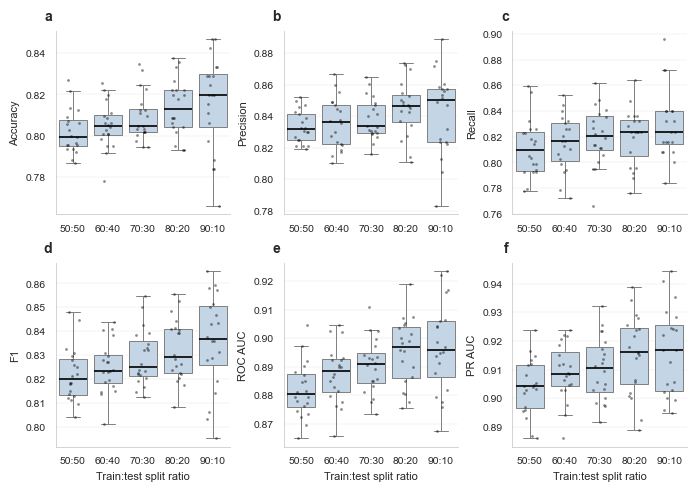

In [27]:
import io
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.linewidth": 0.6, "pdf.fonttype": 42, "ps.fonttype": 42,
})
W, DPI, NAME = 174 / 25.4, 600, "Fig3"
order = list(SPLIT_RATIOS.keys())

fig, axes = plt.subplots(2, 3, figsize=(W, 4.8), constrained_layout=True)
for i, (ax, metric) in enumerate(zip(axes.ravel(), METRICS)):
    sns.boxplot(data=performance_df, x="Split", y=metric, order=order, ax=ax,
                color="#BFD7EA", linewidth=0.7, fliersize=0,
                medianprops={"color": "black", "linewidth": 1.2})
    sns.stripplot(data=performance_df, x="Split", y=metric, order=order, ax=ax,
                  color="black", alpha=0.45, size=2, jitter=0.2)
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_xlabel("Train:test split ratio" if i >= 3 else "")
    ax.text(-0.02, 1.04, "abcdef"[i], transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)
    sns.despine(ax=ax)

fig.savefig(f"{NAME}.pdf")
fig.savefig(f"{NAME}.eps")
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=DPI, facecolor="white")
buf.seek(0)
Image.open(buf).convert("RGB").save(f"{NAME}.tiff", dpi=(DPI, DPI), compression="tiff_lzw")
plt.show()

## 9b. ROC and PR Curves — Mean Across Repeats, Per Ratio

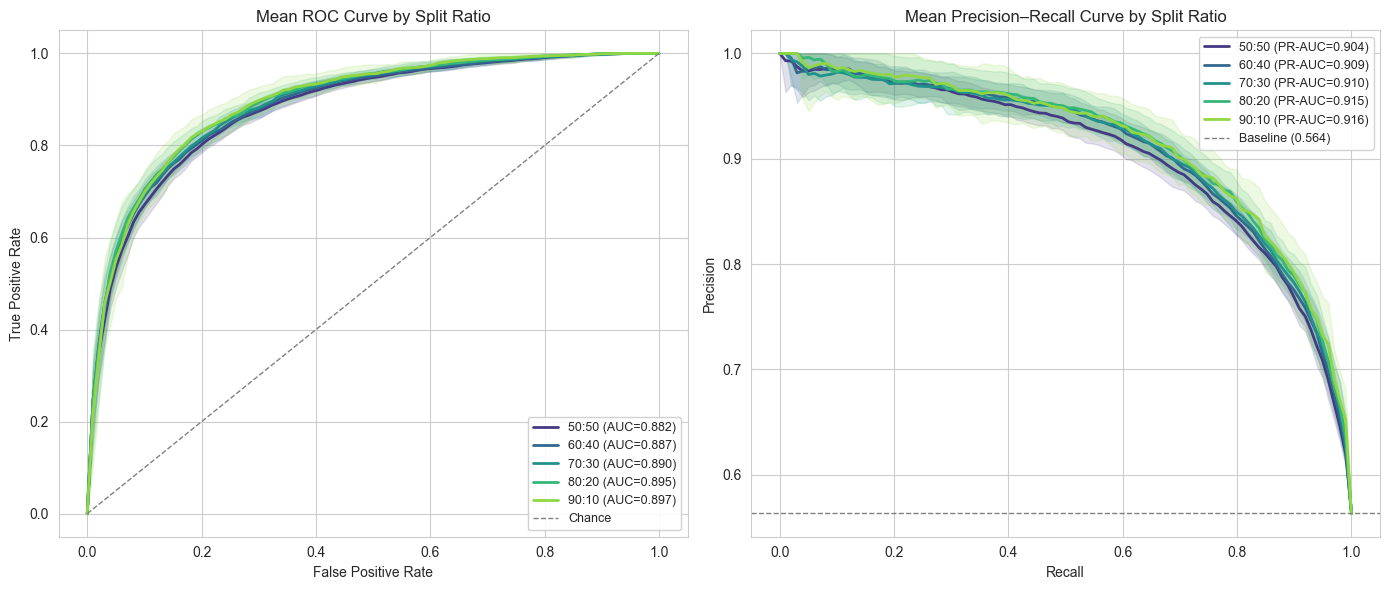

In [17]:

roc_df = pd.DataFrame(roc_curve_records)
pr_df = pd.DataFrame(pr_curve_records)

palette = dict(zip(SPLIT_RATIOS.keys(), sns.color_palette("viridis", n_colors=len(SPLIT_RATIOS))))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
for split_label in SPLIT_RATIOS:
    tprs = np.vstack(roc_df.loc[roc_df["Split"] == split_label, "tpr"].values)
    mean_tpr = tprs.mean(axis=0)
    std_tpr = tprs.std(axis=0)
    mean_roc_auc = summarize_metric(performance_df, "ROC_AUC").loc[split_label, "mean"]

    color = palette[split_label]
    ax.plot(ROC_GRID, mean_tpr, color=color, lw=2, label=f"{split_label} (AUC={mean_roc_auc:.3f})")
    ax.fill_between(ROC_GRID, np.clip(mean_tpr - std_tpr, 0, 1),
                     np.clip(mean_tpr + std_tpr, 0, 1), color=color, alpha=0.15)

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", lw=1, label="Chance")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Mean ROC Curve by Split Ratio")
ax.legend(loc="lower right", fontsize=9, framealpha=0.9)

ax = axes[1]
for split_label in SPLIT_RATIOS:
    precs = np.vstack(pr_df.loc[pr_df["Split"] == split_label, "precision"].values)
    mean_prec = precs.mean(axis=0)
    std_prec = precs.std(axis=0)
    mean_pr_auc = summarize_metric(performance_df, "PR_AUC").loc[split_label, "mean"]

    color = palette[split_label]
    ax.plot(PR_GRID, mean_prec, color=color, lw=2, label=f"{split_label} (PR-AUC={mean_pr_auc:.3f})")
    ax.fill_between(PR_GRID, np.clip(mean_prec - std_prec, 0, 1),
                     np.clip(mean_prec + std_prec, 0, 1), color=color, alpha=0.15)

baseline = df_clean[TARGET].mean()
ax.axhline(baseline, linestyle="--", color="grey", lw=1, label=f"Baseline ({baseline:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Mean Precision\u2013Recall Curve by Split Ratio")
ax.legend(loc="upper right", fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.show()


## 10. Statistical Comparison of Split Ratios — Friedman + Nemenyi

Tests whether the 5 split ratios differ systematically in **PR-AUC** (primary
metric), using each seed as one matched observation per ratio.


In [18]:

PRIMARY_METRIC = "PR_AUC"

wide = performance_df.pivot(index="Seed", columns="Split", values=PRIMARY_METRIC)[list(SPLIT_RATIOS.keys())]
display(wide.style.format("{:.4f}"))

stat, p_value = friedmanchisquare(*[wide[col] for col in wide.columns])
print(f"\nFriedman test on {PRIMARY_METRIC}: statistic={stat:.4f}, p-value={p_value:.4g}")

if p_value < 0.05:
    print("\u2192 Significant difference across split ratios (p < 0.05). Running Nemenyi post-hoc...")
    nemenyi = sp.posthoc_nemenyi_friedman(wide.values)
    nemenyi.index = wide.columns
    nemenyi.columns = wide.columns
    display(nemenyi.style.format("{:.4f}").background_gradient(cmap="RdYlGn_r", vmin=0, vmax=0.1))
    print("(Values are p-values for each pairwise comparison; < 0.05 = significantly different)")
else:
    print("\u2192 No significant difference across split ratios (p \u2265 0.05): "
          f"{PRIMARY_METRIC} does not vary systematically with split ratio in this study.")


Split,50:50,60:40,70:30,80:20,90:10
Seed,,,,,
0,0.8956,0.9112,0.9155,0.9240,0.9169
1,0.9054,0.9049,0.9055,0.9006,0.9049
2,0.9237,0.9238,0.9323,0.9387,0.9245
3,0.9031,0.9046,0.8916,0.9281,0.9354
4,0.8860,0.8977,0.8982,0.9019,0.8960
5,0.8967,0.8941,0.8971,0.8888,0.8994
6,0.9114,0.9116,0.9096,0.9152,0.9027
7,0.9041,0.9119,0.9123,0.9216,0.9219
8,0.8868,0.8860,0.8976,0.9257,0.9300



Friedman test on PR_AUC: statistic=15.8800, p-value=0.003184
→ Significant difference across split ratios (p < 0.05). Running Nemenyi post-hoc...


Split,50:50,60:40,70:30,80:20,90:10
Split,,,,,
50:50,1.0000,0.1152,0.0409,0.0042,0.0086
60:40,0.1152,1.0000,0.9946,0.8066,0.8970
70:30,0.0409,0.9946,1.0000,0.9565,0.9874
80:20,0.0042,0.8066,0.9565,1.0000,0.9996
90:10,0.0086,0.8970,0.9874,0.9996,1.0000


(Values are p-values for each pairwise comparison; < 0.05 = significantly different)


## 11. SHAP Feature Rankings — Aggregated Across Repeats, Per Ratio

For each (seed, ratio), the 10 original features are ranked by mean |SHAP|
(1 = most important; one-hot levels already aggregated back to their source feature
in Section 8's `get_shap_ranking`).


In [19]:

feature_cols = FEATURES

rank_records = []
for _, row in shap_importance_df.iterrows():
    ranks = row[feature_cols].rank(ascending=False)
    rec = {"Seed": row["Seed"], "Split": row["Split"]}
    rec.update(ranks.to_dict())
    rank_records.append(rec)

rank_long_df = pd.DataFrame(rank_records)

mean_rank_by_split = (
    rank_long_df.groupby("Split")[feature_cols].mean().loc[list(SPLIT_RATIOS.keys())].T
)
print("Mean SHAP-importance rank by feature and split (1 = most important, averaged over repeats):")
display(mean_rank_by_split.style.format("{:.2f}").background_gradient(cmap="YlGnBu_r", axis=1))


Mean SHAP-importance rank by feature and split (1 = most important, averaged over repeats):


Split,50:50,60:40,70:30,80:20,90:10
Age,9.70,9.90,9.90,10.00,10.00
Sex,8.80,8.55,8.60,8.30,8.10
ChestPainType,1.00,1.00,1.00,1.00,1.00
RestingBP,2.30,2.10,2.00,2.00,2.00
Cholesterol,5.70,5.75,5.70,5.50,5.45
FastingBS,3.65,3.60,3.65,3.70,3.70
RestingECG,3.35,3.45,3.40,3.30,3.30
MaxHR,8.50,8.55,8.50,8.70,8.90
ExerciseAngina,6.30,6.45,6.55,6.70,6.70
Oldpeak,5.70,5.65,5.70,5.80,5.85


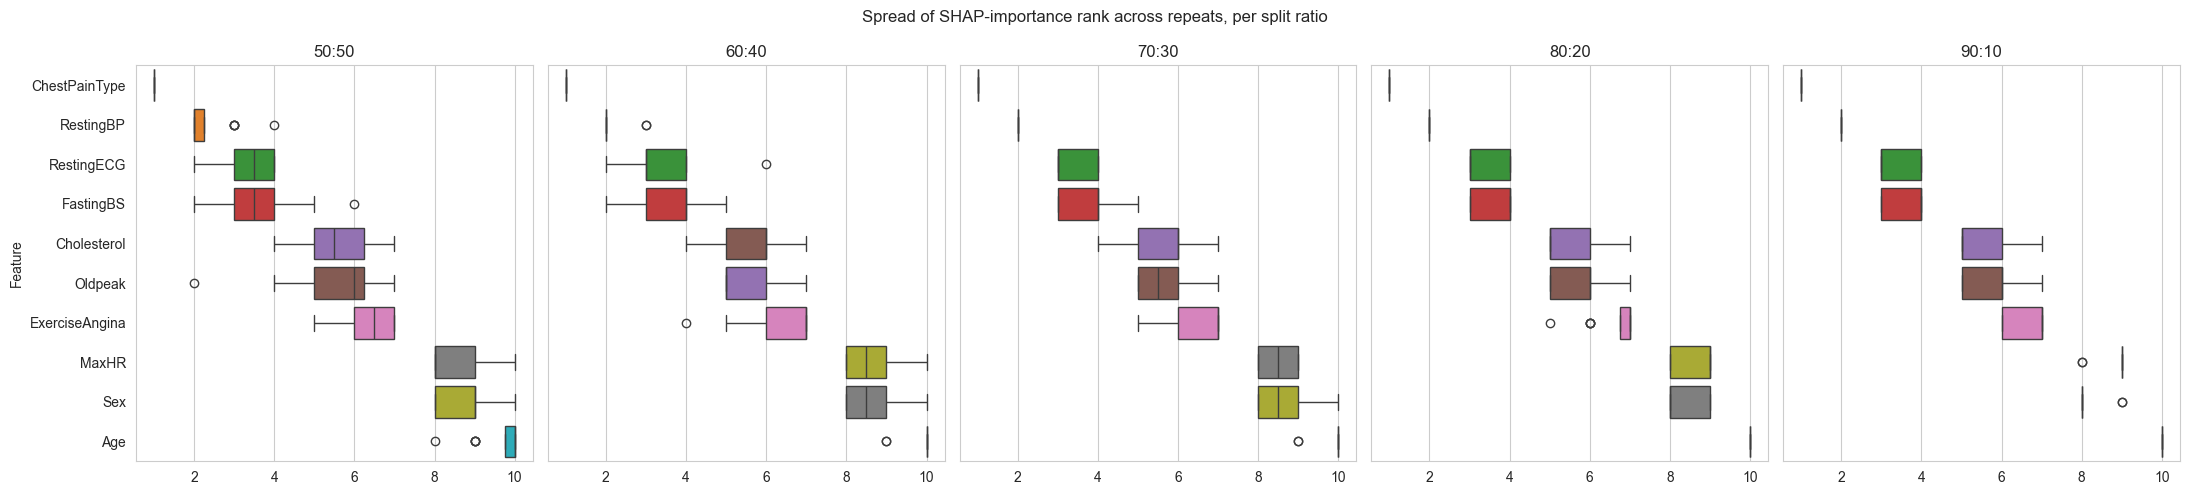

In [20]:

fig, axes = plt.subplots(1, len(SPLIT_RATIOS), figsize=(22, 5), sharey=True)
for ax, split_label in zip(axes, SPLIT_RATIOS):
    sub = rank_long_df[rank_long_df["Split"] == split_label][feature_cols]
    order = sub.mean().sort_values().index
    sns.boxplot(data=sub[order], orient="h", ax=ax)
    ax.set_title(split_label)
axes[0].set_ylabel("Feature")
plt.suptitle("Spread of SHAP-importance rank across repeats, per split ratio")
plt.tight_layout()
plt.show()


### 11.1 Mean |SHAP| Magnitude by Split — Side-by-Side Subplots

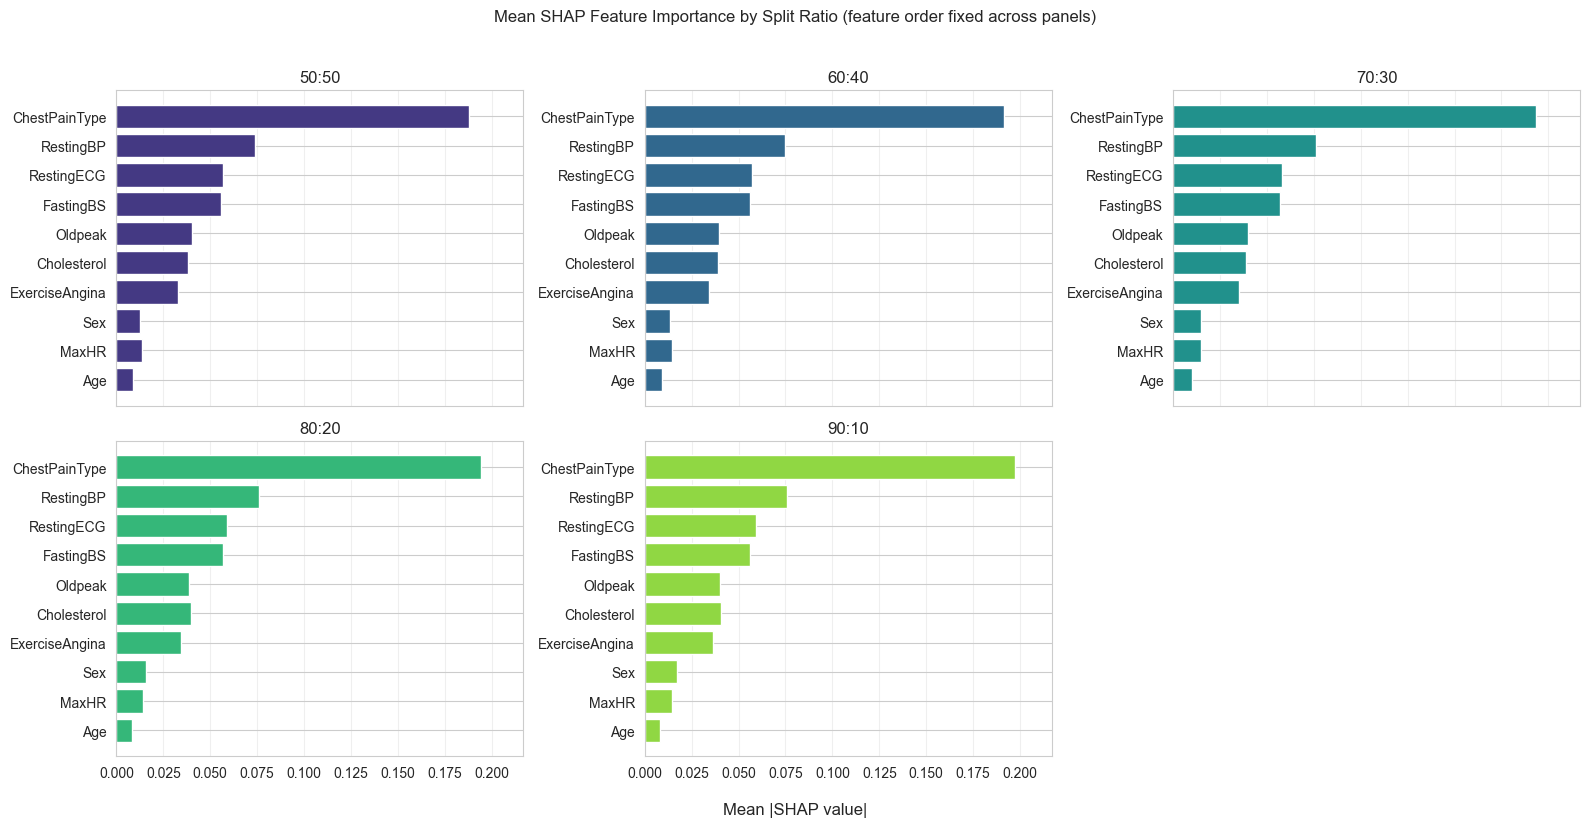

In [21]:

mean_magnitude_by_split = (
    shap_importance_df.groupby("Split")[feature_cols].mean().loc[list(SPLIT_RATIOS.keys())]
)
global_order = mean_magnitude_by_split.mean(axis=0).sort_values(ascending=True).index
x_max = mean_magnitude_by_split.values.max() * 1.1

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
axes = axes.ravel()

for ax, split_label in zip(axes, SPLIT_RATIOS):
    values = mean_magnitude_by_split.loc[split_label, global_order]
    colors = [palette[split_label]] * len(values)
    ax.barh(global_order, values, color=colors)
    ax.set_title(split_label)
    ax.set_xlim(0, x_max)
    ax.grid(axis="x", alpha=0.3)

axes[-1].axis("off")

fig.supxlabel("Mean |SHAP value|")
plt.suptitle("Mean SHAP Feature Importance by Split Ratio (feature order fixed across panels)", y=1.02)
plt.tight_layout()
plt.show()


## 12. Explanation Stability Across Split Ratios

All 10 pairwise ratio comparisons, using mean rank per feature per ratio
(Section 11):

- **Kendall's τ** — rank agreement between two rankings
- **Spearman's ρ** — correlation between rank positions
- **Jaccard similarity, Top-3 and Top-5** — set overlap of the most important
  features (Top-10 is not used: with only 10 predictors it would trivially always
  equal the full feature set and carry no discriminative value — same reasoning as
  Experiment 1's 8-predictor case)
- **Mean absolute rank difference** — average shift in rank position per feature


In [22]:

def jaccard(set_a, set_b):
    set_a, set_b = set(set_a), set(set_b)
    return len(set_a & set_b) / len(set_a | set_b)

splits_list = list(SPLIT_RATIOS.keys())
pairs = [(a, b) for i, a in enumerate(splits_list) for b in splits_list[i + 1:]]

consistency_rows = []
for a, b in pairs:
    rank_a = mean_rank_by_split[a]
    rank_b = mean_rank_by_split[b]

    tau, _ = kendalltau(rank_a, rank_b)
    rho, _ = spearmanr(rank_a, rank_b)

    top3_a, top3_b = rank_a.nsmallest(3).index, rank_b.nsmallest(3).index
    top5_a, top5_b = rank_a.nsmallest(5).index, rank_b.nsmallest(5).index

    mean_abs_diff = (rank_a - rank_b).abs().mean()

    consistency_rows.append({
        "Split_A": a, "Split_B": b,
        "Kendall_tau": tau, "Spearman_rho": rho,
        "Jaccard_top3": jaccard(top3_a, top3_b),
        "Jaccard_top5": jaccard(top5_a, top5_b),
        "Mean_abs_rank_diff": mean_abs_diff,
    })

consistency_df = pd.DataFrame(consistency_rows)
display(consistency_df.style.format({
    "Kendall_tau": "{:.3f}", "Spearman_rho": "{:.3f}",
    "Jaccard_top3": "{:.3f}", "Jaccard_top5": "{:.3f}", "Mean_abs_rank_diff": "{:.3f}",
}))


,Split_A,Split_B,Kendall_tau,Spearman_rho,Jaccard_top3,Jaccard_top5,Mean_abs_rank_diff
0,50:50,60:40,0.977,0.994,1.000,0.667,0.110
1,50:50,70:30,1.000,1.000,1.000,1.000,0.100
2,50:50,80:20,0.944,0.985,1.000,1.000,0.210
3,50:50,90:10,0.944,0.985,1.000,1.000,0.260
4,60:40,70:30,0.977,0.994,1.000,0.667,0.050
5,60:40,80:20,0.944,0.985,1.000,0.667,0.150
6,60:40,90:10,0.944,0.985,1.000,0.667,0.200
7,70:30,80:20,0.944,0.985,1.000,1.000,0.120
8,70:30,90:10,0.944,0.985,1.000,1.000,0.170
9,80:20,90:10,1.000,1.000,1.000,1.000,0.050


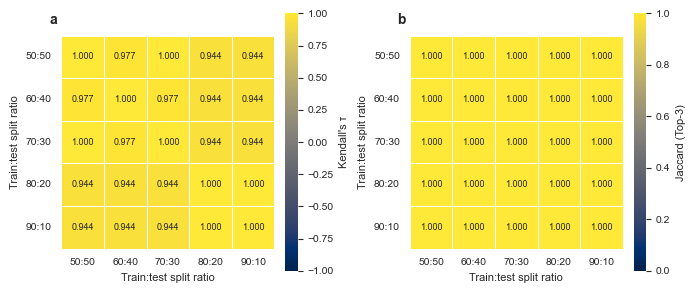

In [26]:
import io
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.linewidth": 0.6, "pdf.fonttype": 42, "ps.fonttype": 42,
})
W, DPI, NAME = 174 / 25.4, 600, "Fig4"

def to_square(df, value_col):
    sq = pd.DataFrame(index=splits_list, columns=splits_list, dtype=float)
    for _, row in df.iterrows():
        sq.loc[row["Split_A"], row["Split_B"]] = row[value_col]
        sq.loc[row["Split_B"], row["Split_A"]] = row[value_col]
    diag_val = 1.0 if value_col != "Mean_abs_rank_diff" else 0.0
    for s in splits_list:
        sq.loc[s, s] = diag_val
    return sq.astype(float)

fig, axes = plt.subplots(1, 2, figsize=(W, 3.3), constrained_layout=True)
panels = [("Kendall_tau", -1, 1, "Kendall's \u03c4"),
          ("Jaccard_top3", 0, 1, "Jaccard (Top-3)")]
for i, (ax, (col, vmin, vmax, lab)) in enumerate(zip(axes, panels)):
    sns.heatmap(to_square(consistency_df, col), annot=True, fmt=".3f",
                annot_kws={"size": 6.5}, cmap="cividis", vmin=vmin, vmax=vmax,
                linewidths=0.4, linecolor="white", square=True, ax=ax,
                cbar_kws={"shrink": 0.8, "label": lab})
    ax.set_xlabel("Train:test split ratio")
    ax.set_ylabel("Train:test split ratio")
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=0)
    ax.text(-0.02, 1.04, "ab"[i], transform=ax.transAxes,
            fontsize=10, fontweight="bold", va="bottom", ha="right")

fig.savefig(f"{NAME}.pdf")
fig.savefig(f"{NAME}.eps")
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=DPI, facecolor="white")
buf.seek(0)
Image.open(buf).convert("RGB").save(f"{NAME}.tiff", dpi=(DPI, DPI), compression="tiff_lzw")
plt.show()

In [24]:

print("Summary consistency statistics across all 10 ratio-pairs:")
display(consistency_df[["Kendall_tau", "Spearman_rho", "Jaccard_top3",
                          "Jaccard_top5", "Mean_abs_rank_diff"]].describe().loc[["mean", "std", "min", "max"]])


Summary consistency statistics across all 10 ratio-pairs:


,Kendall_tau,Spearman_rho,Jaccard_top3,Jaccard_top5,Mean_abs_rank_diff
mean,0.961782,0.989665,1.0,0.866667,0.142000
std,0.024322,0.006592,0.0,0.172133,0.069089
min,0.943880,0.984807,1.0,0.666667,0.050000
max,1.000000,1.000000,1.0,1.000000,0.260000


## 13. The Performance–Stability Gap: Does the Best-Performing Ratio Also Give the Most Stable Explanation?

Exploratory, not assumed: is the split ratio with the strongest mean PR-AUC also the
one whose feature ranking is most stable (highest mean τ against the other four)?
Mean τ values are compared at three decimal places, and any ties for the highest value
are reported as ties rather than broken arbitrarily.


In [25]:

best_ratio_by_perf = summarize_metric(performance_df, "PR_AUC")["mean"].idxmax()

mean_tau_per_split = {}
for s in splits_list:
    taus = [row["Kendall_tau"] for _, row in consistency_df.iterrows()
            if s in (row["Split_A"], row["Split_B"])]
    mean_tau_per_split[s] = np.mean(taus)

# Ties are judged at the same 3-decimal precision that is reported
tau_rounded = {s: round(v, 3) for s, v in mean_tau_per_split.items()}
max_tau = max(tau_rounded.values())
most_stable_ratios = [s for s, v in tau_rounded.items() if v == max_tau]

print(f"Best-performing ratio (mean PR-AUC across {N_REPEATS} repeats): {best_ratio_by_perf}")
print(f"Most stable ratio(s) (highest mean Kendall's tau vs. the other 4): "
      f"{', '.join(most_stable_ratios)}  (tau = {max_tau:.3f})")
print("\nMean tau per ratio:")
for s, v in mean_tau_per_split.items():
    print(f"  {s}: {v:.3f}")

if best_ratio_by_perf in most_stable_ratios and len(most_stable_ratios) == 1:
    print("\n→ The best-performing ratio is ALSO the single most stable ratio for explanations.")
elif best_ratio_by_perf in most_stable_ratios:
    print("\n→ The best-performing ratio is TIED for the most stable explanations "
          f"(with {', '.join(r for r in most_stable_ratios if r != best_ratio_by_perf)}).")
else:
    print("\n→ Performance and explanation stability point to DIFFERENT ratios — "
          "the performance–stability gap. Worth discussing as a finding, not "
          "collapsing into a single 'best' recommendation.")


Best-performing ratio (mean PR-AUC across 20 repeats): 90:10
Most stable ratio(s) (highest mean Kendall's tau vs. the other 4): 50:50, 70:30  (tau = 0.966)

Mean tau per ratio:
  50:50: 0.966
  60:40: 0.961
  70:30: 0.966
  80:20: 0.958
  90:10: 0.958

→ Performance and explanation stability point to DIFFERENT ratios — the performance–stability gap. Worth discussing as a finding, not collapsing into a single 'best' recommendation.


## 14. Limitations

State explicitly in the write-up:

1. **Two datasets, one algorithm** — an improvement on a single-dataset design, but
   still not sweeping evidence of generalizability. Findings describe Random Forest on
   the Pima Indians Diabetes Dataset (Experiment 1) and this combined UCI Heart Disease
   Dataset (Experiment 2) under matched preprocessing philosophies (not identical
   preprocessing — see points 4 and 5) — not a general claim across arbitrary clinical
   datasets or algorithms.
2. **Merge-artifact duplication.** 723 of 2,943 rows (24.6%) were removed as exact
   duplicates arising from the five-cohort merge. This is the right call for the
   reasons given in Section 4, but it also means the "n=2,943" figure often quoted
   for this dataset release overstates the number of independent observations
   actually analyzed here (n=2,220).
3. **Test-set size varies by ratio** (from ~222 observations at 90:10 to ~1,110 at
   50:50), affecting the precision of SHAP estimates independently of the ratio
   itself. Repeating each ratio 20 times and reporting aggregated (mean-rank)
   statistics mitigates, but does not eliminate, this confound — identical caveat to
   Experiment 1.
4. **Preprocessing is matched in philosophy, not in literal structure, across
   experiments.** Experiment 1 has no categorical branch; Experiment 2's categorical
   features genuinely exercise one-hot encoding. This is a necessary consequence of
   the two datasets' actual feature types — but it means a direct numeric comparison
   of, e.g., SHAP magnitude scales between experiments is not meaningful; only
   rank-based and stability-based comparisons (see the cross-study synthesis in the manuscript) are.
5. **Preprocessing differs between experiments.** Experiment 1 uses MICE imputation
   (heavy missingness in Pima); this experiment uses median imputation (little
   missingness). Both use Random Forest class weighting rather than SMOTE, but
   preprocessing is matched in philosophy, not identical, across the two datasets.
6. **Retuning per repeat** (Section 7/8) means reported variability reflects both
   sampling variability and hyperparameter-search stochasticity in both experiments,
   not sampling variability alone.
